# Population size estimation with skyline / constant coalescent prior

In [1]:
from Bio import Nexus, Phylo, SeqIO
from collections import defaultdict
from io import StringIO

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

import pandas as pd
import numpy as np

import re
from pathlib import Path

from itertools import combinations
from evaluation_helpers import *

## Successful runs
In this notebook, we start analysing the results of the simulation study, starting with population size. To do so, we first need to check, how many replicate trees ran successfully in each setting.

In [2]:
pd.read_csv("../results/run1/evaluation/successful_counts.tsv", sep = "\t")

,sampling,population_model,mutation_signal,n_successful
0,independenthomochronous,bottleneck,high,80
1,independenthomochronous,bottleneck,low,56
2,independenthomochronous,bottleneck,med,76
3,independenthomochronous,expgrowthfast,high,91
4,independenthomochronous,expgrowthfast,low,91
5,independenthomochronous,expgrowthfast,med,97
6,independenthomochronous,expgrowthslow,high,97
7,independenthomochronous,expgrowthslow,low,90
8,independenthomochronous,expgrowthslow,med,96
9,independenthomochronous,uniform,high,81


## Population size estimates

First, we need to load the population-size estimates written by the `compute_errors` step of the Snakemake pipeline (`scripts/compute_errors.py`):

  - **`df_pop_info`** (`load_pop_summaries`): reads all `*_pop_summary.pkl` files and keeps one row per replicate tree. Each row has the posterior median and 95% HPD of the constant-coalescent population size and of each
  skyline interval, the median skyline interval boundaries, 100 subsampled posterior draws, and tree-length error summaries. Each replicate's true simulation parameters (present population size, growth rate, bottleneck size
  and timing) are merged in from the scenario TSVs.
  - **`traj_df`** (`load_pop_trajectories`): reads all `*_pop_trajectory.tsv` files. For each scenario, it pools all posterior samples across replicates and gives the median and 95% HPD of the skyline and constant-coalescent
  population size on a time grid from 0 to 500.

  `plot_population_summary` uses `df_pop_info` for per-replicate summaries and `trajectory_df=traj_df` for plotting the pooled posterior trajectory, considering posterior samples of all successful replicate runs per scenario.

In [16]:
df_pop_info = load_pop_summaries("../results/run1/evaluation")
traj_df = load_pop_trajectories("../results/run1/evaluation")
df_pop_info.head()

,sampling,population_model,mutation_signal,tree_index,skyline_times,skyline_medians,skyline_lowers,skyline_uppers,skyline_samples,skyline_times_samples,...,skyline_height_rel_error_hpd_lower,skyline_height_rel_error_hpd_upper,skyline_height_abs_rel_error_median,skyline_height_abs_rel_error_hpd_lower,skyline_height_abs_rel_error_hpd_upper,present_pop_size,growth_rate,bottleneck_size,bottleneck_start,bottleneck_end
0,independenthomochronous,bottleneck,high,0,"[1.4766475121491567, 1.936933946825775, 2.7924...","[1539.7790587904333, 364.72642362756756, 568.9...","[788.7031515101185, 48.09414458616408, 204.320...","[2442.7797527796133, 1009.5813460576722, 1178....",0 1 2 ...,0 1 2 3 ...,...,-0.999780,1.976007,0.219272,1.613809e-06,1.975971,1000,NaN,100.0,20.0,23.0
1,independenthomochronous,bottleneck,high,1,"[0.7972796095147032, 2.283983509613563, 3.3353...","[870.183332578285, 1227.7435827097408, 662.569...","[341.30491645982335, 322.8526958585132, 110.90...","[1651.6094209640742, 2109.52343929743, 1507.32...",0 1 2 ...,0 1 2 3 ...,...,-0.999972,1.878092,0.217775,1.257787e-06,1.878092,1000,NaN,100.0,20.0,23.0
2,independenthomochronous,bottleneck,high,2,"[0.6745245198007979, 1.4017453323986047, 2.497...","[728.75977974291, 591.7736735048368, 657.65410...","[254.0855896756848, 96.85047836117484, 162.428...","[1396.313045847564, 1328.4629454806836, 1368.1...",0 1 2 ...,0 1 2 3 ...,...,-0.999985,1.808220,0.236929,3.309909e-06,1.808220,1000,NaN,100.0,20.0,23.0
3,independenthomochronous,bottleneck,high,3,"[1.0983578731604666, 3.140976440498889, 4.6544...","[1226.2631616243966, 1658.709338766412, 955.15...","[528.0302082404304, 425.2173202434592, 178.501...","[2201.8022083351498, 2822.6265810398577, 2064....",0 1 2 ...,0 1 2 3 ...,...,-0.999905,1.811305,0.218756,7.694055e-07,1.811290,1000,NaN,100.0,20.0,23.0
4,independenthomochronous,bottleneck,high,4,"[1.2059733820469773, 2.060165011666868, 3.3035...","[1289.081011837042, 691.6623577699729, 774.274...","[590.3474220426203, 110.90377012142191, 158.90...","[2249.5010188577944, 1614.283109901542, 1543.0...",0 1 2 ...,0 1 2 3 ...,...,-0.999917,1.897541,0.226753,6.065042e-07,1.897541,1000,NaN,100.0,20.0,23.0


In [17]:
# median population size across replicates and posterior samples for the constant coalescent prior

traj_df.groupby(['sampling', 'population_model', 'mutation_signal'])['constcoal_median'].unique()
# traj_df.groupby(['sampling', 'population_model', 'mutation_signal'])['constcoal_hpd_upper'].unique()
# traj_df.groupby(['sampling', 'population_model', 'mutation_signal'])['constcoal_hpd_lower'].unique()

sampling                 population_model  mutation_signal
independenthomochronous  bottleneck        high                [858.9588662887074]
                                           low                 [849.7876949297618]
                                           med                 [848.6323458041027]
                         expgrowthfast     high                [1343.695104424477]
                                           low                [1170.8745841607338]
                                           med                [1301.6954715350043]
                         expgrowthslow     high               [1532.8450494796498]
                                           low                [1370.5938223445924]
                                           med                [1519.5169751445787]
                         uniform           high               [1013.5926950857612]
                                           low                [1020.5284388205936]
                            

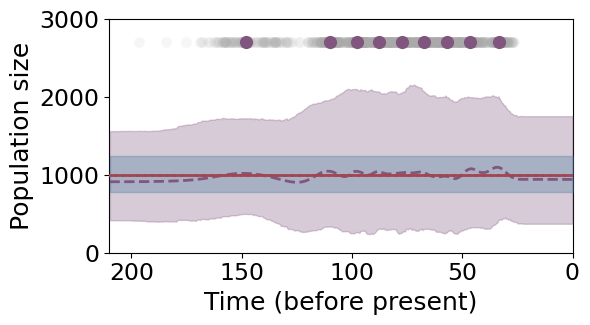

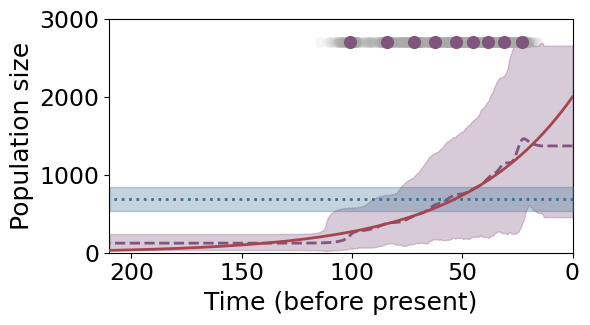

In [18]:
# plot population size trajectories

plot_population_summary(df_pop_info, trajectory_df = traj_df,sampling="linearconstant", title = "", x_range = (0,210), y_range = (0,3000), add_samples=False, mode = 'both',
                        pop_models = ["uniform"], mut_signals=["low"], show_pop_model_labels=False, show_mutsig_labels=False, show_legend = False,
                        show_changepoints=True, changepoint_dot_size=60, changepoint_grey_alpha=0.1,
                        y_label="Population size", x_label = "Time (before present)", figsize=(6, 3.5), label_fontsize=18, tick_fontsize=17,
                        save_path = "../figures/population_size/population_size_overview_uniform_200_trajectory_linearconstant.pdf")

plot_population_summary(df_pop_info, trajectory_df = traj_df,sampling="linearconstant", title = "", x_range = (0,210), y_range = (0,3000), add_samples=False, mode = 'both',
                        pop_models = ["expgrowthfast"], mut_signals=["low"], show_pop_model_labels=False, show_mutsig_labels=False, show_legend = False,
                        show_changepoints=True, changepoint_dot_size=60, changepoint_grey_alpha=0.1,
                        y_label="Population size", x_label = "Time (before present)", figsize=(6, 3.5), label_fontsize=18, tick_fontsize=17,
                        save_path = "../figures/population_size/population_size_overview_expgrowthfast_200_trajectory_linearconstant.pdf")

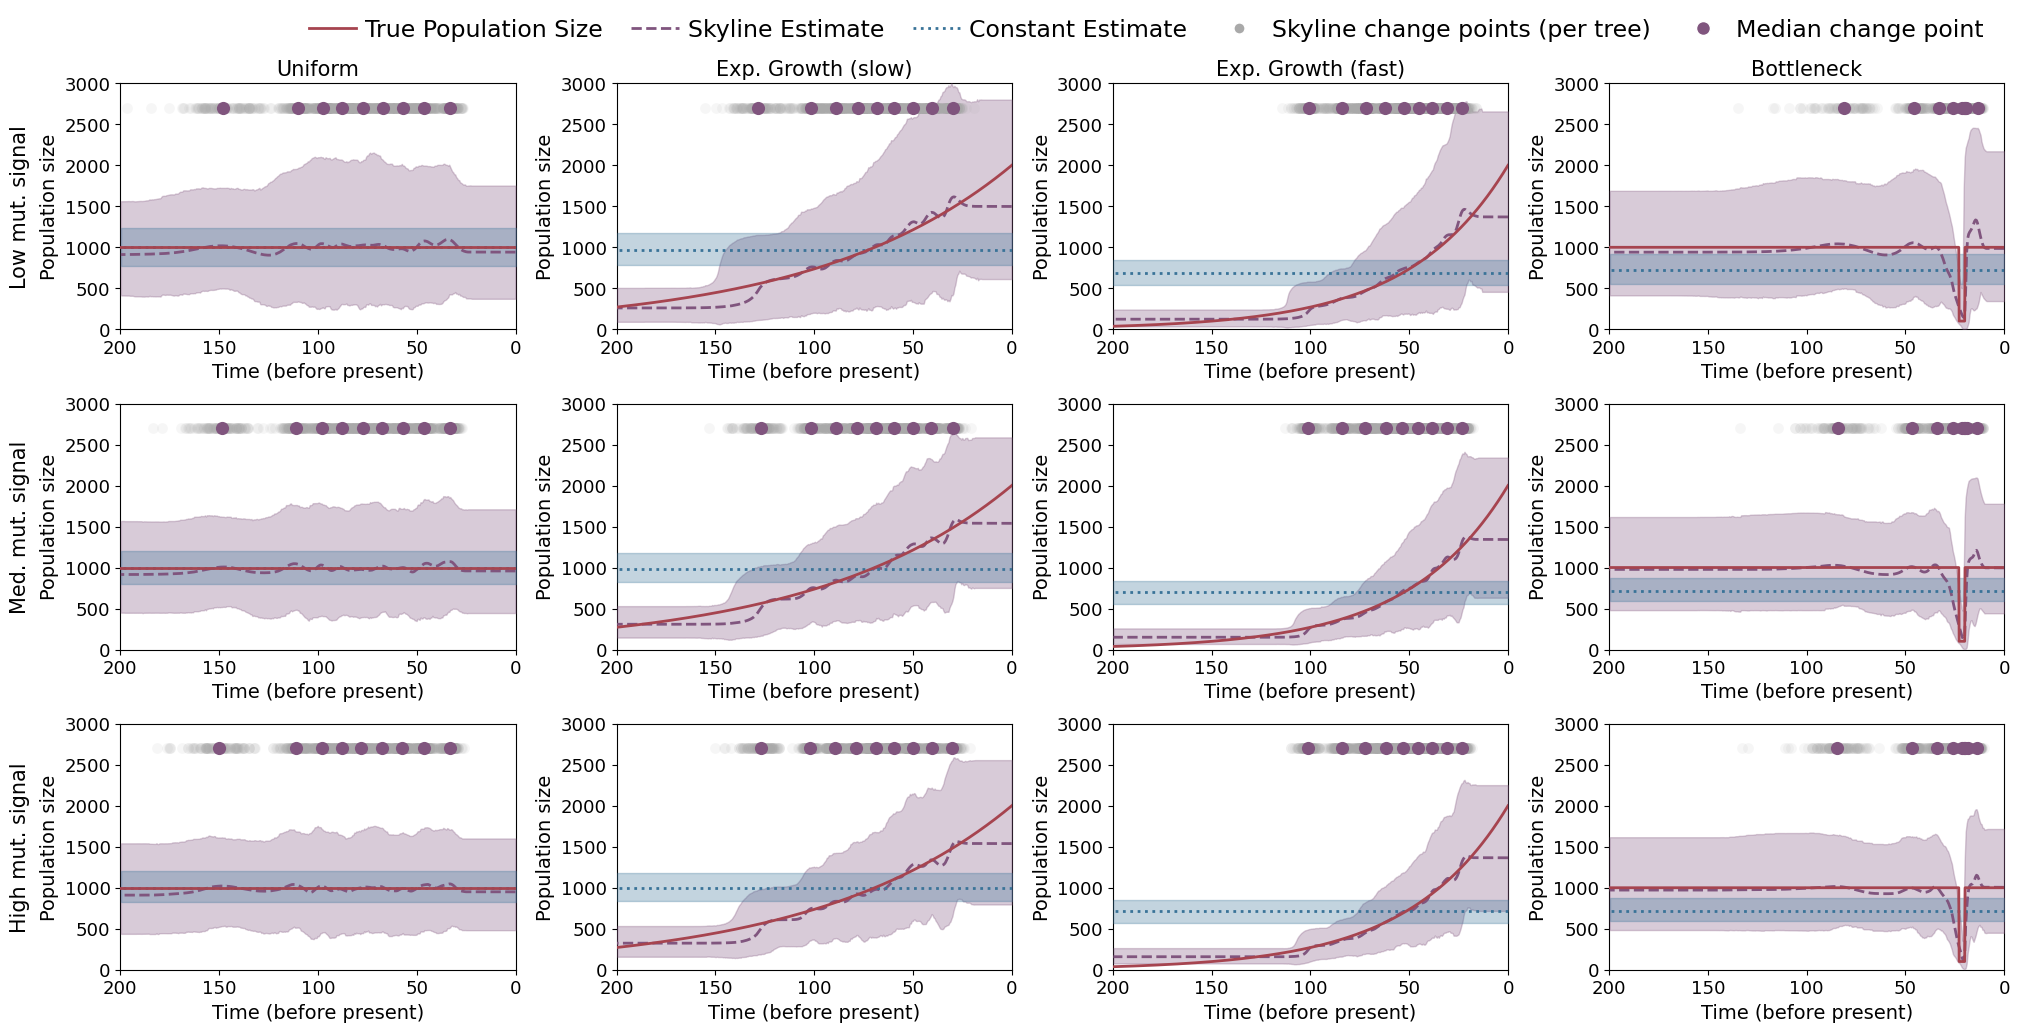

In [19]:
# heterochronous sampling
plot_population_summary(df_pop_info, trajectory_df = traj_df,sampling="linearconstant", title = "", x_range = (0,200), y_range = (0,3000), add_samples=False, mode = 'both', pop_models = ["uniform", "expgrowthslow", "expgrowthfast", "bottleneck"],
                        show_changepoints=True, changepoint_dot_size=60, changepoint_grey_alpha=0.1,
                        label_fontsize=14, tick_fontsize=13, legend_fontsize=17,
                        y_label="Population size", x_label = "Time (before present)",
                        save_path = "../figures/population_size/population_size_overview_all_200_trajectory_linearconstant.pdf")

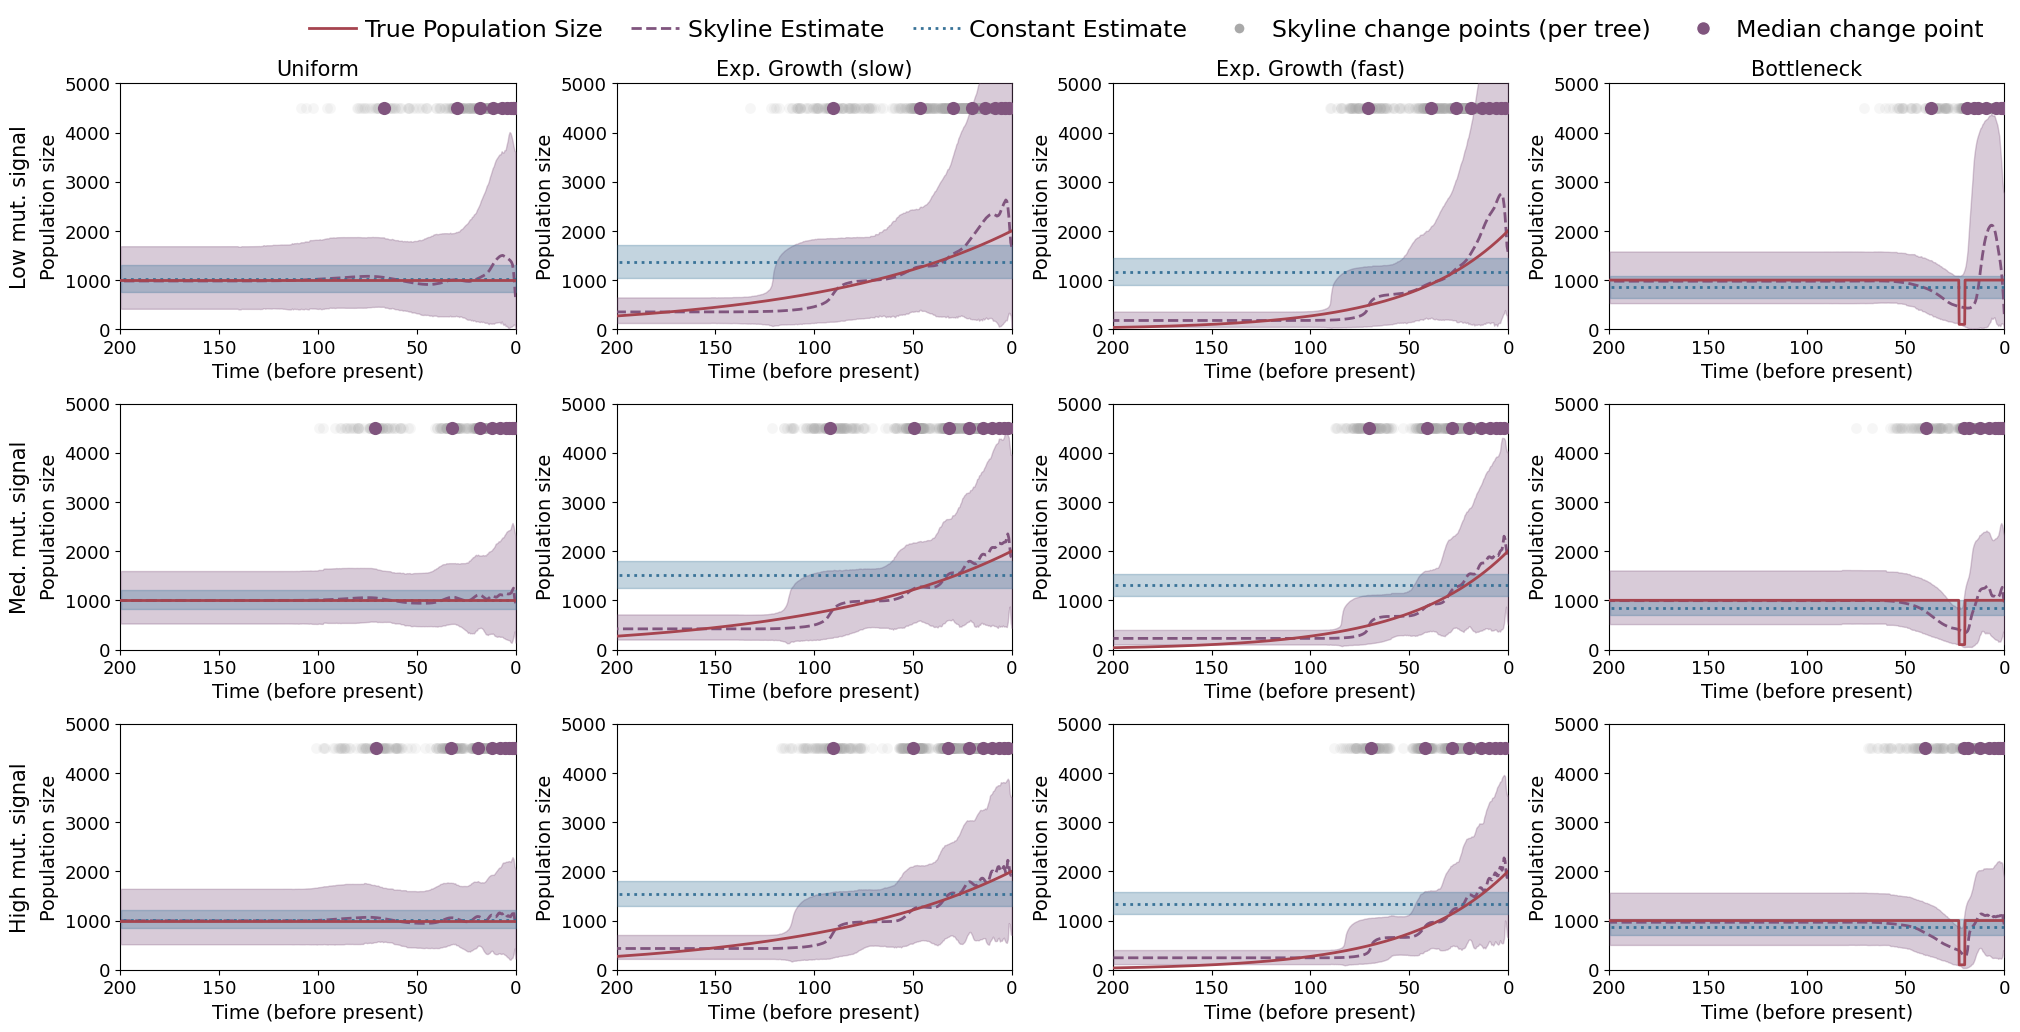

In [20]:
# homochronous sampling
plot_population_summary(df_pop_info,  trajectory_df = traj_df, sampling="independenthomochronous", title = "", x_range = (0,200), y_range = (0,5000), add_samples=False, mode = 'both', pop_models = ["uniform", "expgrowthslow", "expgrowthfast", "bottleneck"],
                        show_changepoints=True, changepoint_dot_size=60, changepoint_grey_alpha=0.1,
                        label_fontsize=14, tick_fontsize=13, legend_fontsize=17,
                        y_label="Population size", x_label = "Time (before present)",
                        save_path = "../figures/population_size/population_size_overview_all_200_trajectory_independenthomochronous.pdf")